In [1]:
# Step1- Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Step 2-Load Dataset

In [4]:
df=pd.read_csv(r"C:\Users\rutuk\Downloads\archive (12)\crop_production.csv")
df.head()

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [5]:
# Step3 - Exploring Dataset

In [6]:
df.shape

(246091, 7)

In [7]:
df.columns

Index(['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area',
       'Production'],
      dtype='str')

In [8]:
df.dtypes

State_Name           str
District_Name        str
Crop_Year          int64
Season               str
Crop                 str
Area             float64
Production       float64
dtype: object

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  str    
 1   District_Name  246091 non-null  str    
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  str    
 4   Crop           246091 non-null  str    
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 22.0 MB


In [10]:
df.describe()

,Crop_Year,Area,Production
count,246091.000000,2.460910e+05,2.423610e+05
mean,2005.643018,1.200282e+04,5.825034e+05
std,4.952164,5.052340e+04,1.706581e+07
min,1997.000000,4.000000e-02,0.000000e+00
25%,2002.000000,8.000000e+01,8.800000e+01
50%,2006.000000,5.820000e+02,7.290000e+02
75%,2010.000000,4.392000e+03,7.023000e+03
max,2015.000000,8.580100e+06,1.250800e+09


In [11]:
df.describe(include='object')

,State_Name,District_Name,Season,Crop
count,246091,246091,246091,246091
unique,33,646,6,124
top,Uttar Pradesh,BIJAPUR,Kharif,Rice
freq,33306,945,95951,15104


In [12]:
# Checking Missing values

In [13]:
df.isnull().sum()

State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64

In [14]:
#Checking Duplicates

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
print("Negative Area:",(df["Area"]<0).sum())
print("Negative Production:",(df["Production"]<0).sum())
print("Zero Area:",(df["Area"]==0).sum())

Negative Area: 0
Negative Production: 0
Zero Area: 0


In [17]:
#Separate out numerical columns &categorical columns

In [18]:
numerical_cols=df.select_dtypes(include='number').columns
numerical_cols

Index(['Crop_Year', 'Area', 'Production'], dtype='str')

In [19]:
categorical_cols=df.select_dtypes(include='object').columns
categorical_cols

Index(['State_Name', 'District_Name', 'Season', 'Crop'], dtype='str')

In [20]:
#checking outliers for imputation of missing values

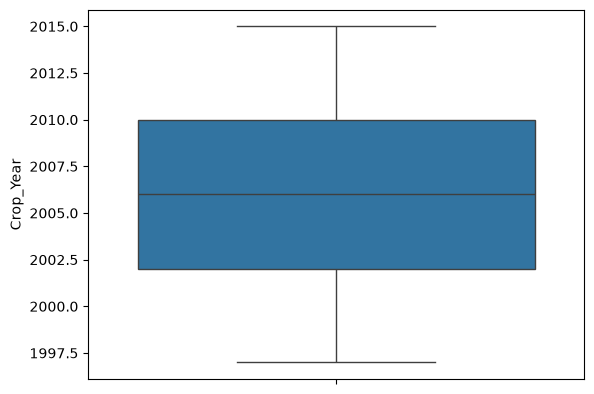

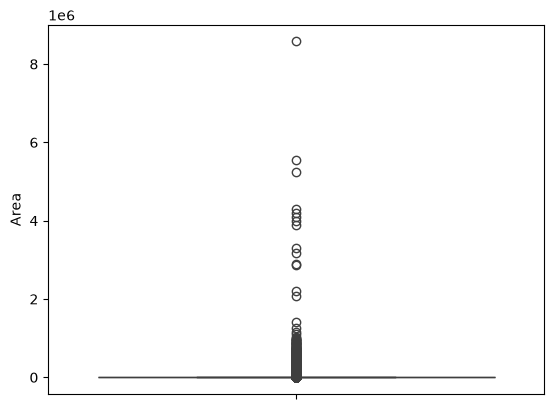

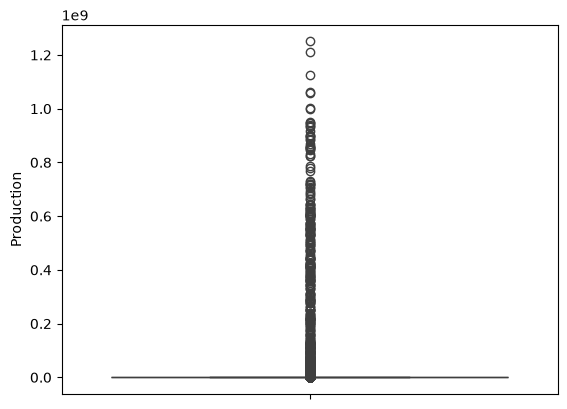

In [21]:
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [22]:
#Handling Missing Values

In [23]:
df["Production"]=df["Production"].fillna(df["Production"].median())

In [24]:
df.isnull().sum()

State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
dtype: int64

In [25]:
#Handling Outliers

In [26]:
for i in numerical_cols:
    Q1=df[i].quantile(0.25)
    Q3=df[i].quantile(0.75)

    IQR=Q3-Q1

    Lower=Q1-1.5*IQR
    Upper=Q3+1.5*IQR

    outliers=((df[i]<Lower)|(df[i]>Upper)).sum()

    print(i,"=",outliers)

Crop_Year = 0
Area = 40705
Production = 43062


In [27]:
#Cap Outliers

In [28]:
for i in numerical_cols:
    Q1=df[i].quantile(0.25)
    Q3=df[i].quantile(0.75)

    IQR=Q3-Q1

    Lower=Q1-1.5*IQR
    Upper=Q3+1.5*IQR
    df[i]=df[i].clip(Lower,Upper)

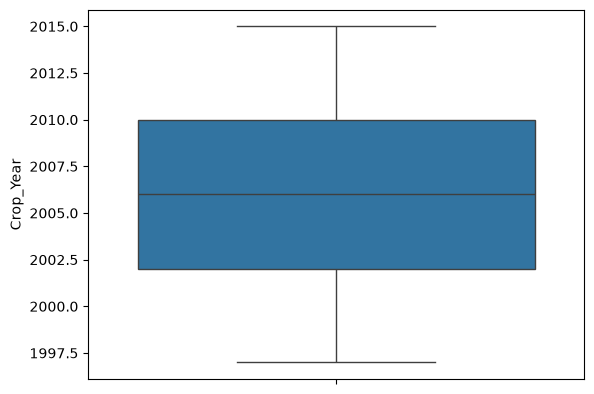

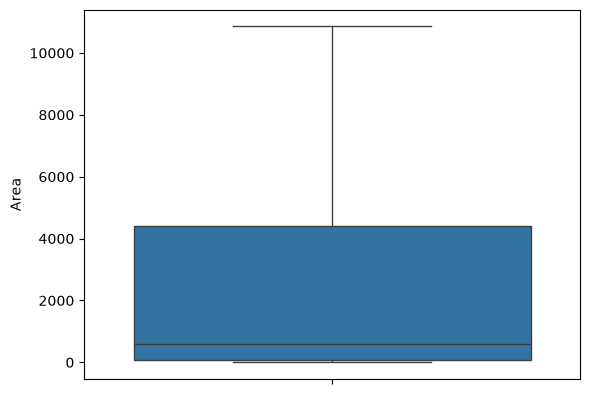

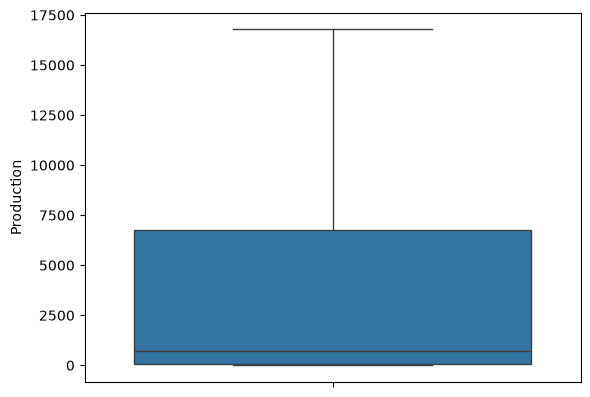

In [29]:
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [30]:
df.describe(include="number")

,Crop_Year,Area,Production
count,246091.000000,246091.000000,246091.000000
mean,2005.643018,2910.964439,4470.866308
std,4.952164,4070.178581,6406.039024
min,1997.000000,0.040000,0.000000
25%,2002.000000,80.000000,91.000000
50%,2006.000000,582.000000,729.000000
75%,2010.000000,4392.000000,6769.000000
max,2015.000000,10860.000000,16786.000000


In [31]:
#Adding new column

In [32]:
df['Yield']=np.where(df['Area']>0,df["Production"]/df["Area"],np.nan)

In [33]:
df[["Crop","Area","Production","Yield"]].head()

,Crop,Area,Production,Yield
0,Arecanut,1254.0,2000.0,1.594896
1,Other Kharif pulses,2.0,1.0,0.500000
2,Rice,102.0,321.0,3.147059
3,Banana,176.0,641.0,3.642045
4,Cashewnut,720.0,165.0,0.229167


In [34]:
df.isnull().sum()

State_Name       0
District_Name    0
Crop_Year        0
Season           0
Crop             0
Area             0
Production       0
Yield            0
dtype: int64

In [35]:
df["Yield"].describe()

count    246091.000000
mean          8.509832
std         130.830439
min           0.000000
25%           0.555065
50%           1.122846
75%           1.862184
max       18225.000000
Name: Yield, dtype: float64

In [36]:
df["State_Name"].nunique()

33

In [37]:
df["District_Name"].nunique()

646

In [38]:
df["Crop"].nunique()

124

In [39]:
df["Season"].nunique()

6

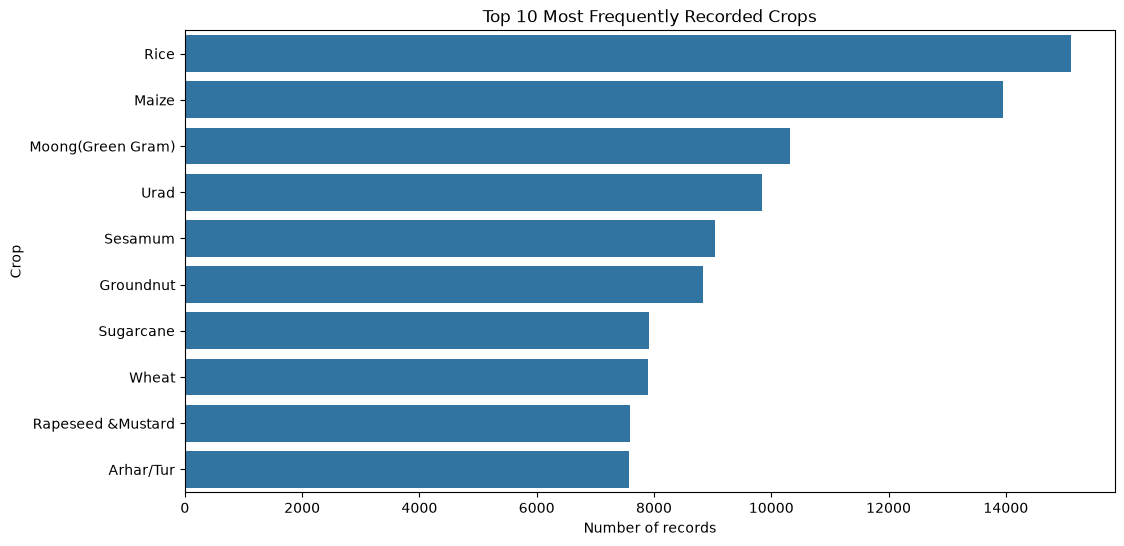

In [40]:
top_crops=df["Crop"].value_counts().head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=top_crops.values,y=top_crops.index)
plt.title("Top 10 Most Frequently Recorded Crops")
plt.xlabel("Number of records")
plt.ylabel("Crop")
plt.show()

#### Interpretation:- Rice is the most frequently recorded crop in the dataset. This indicates that rice has greater representation in the available agricultural records. However, record frequency does not necessarily mean that rice has the highest production or cultivated area.

In [41]:
#Univariate Analysis

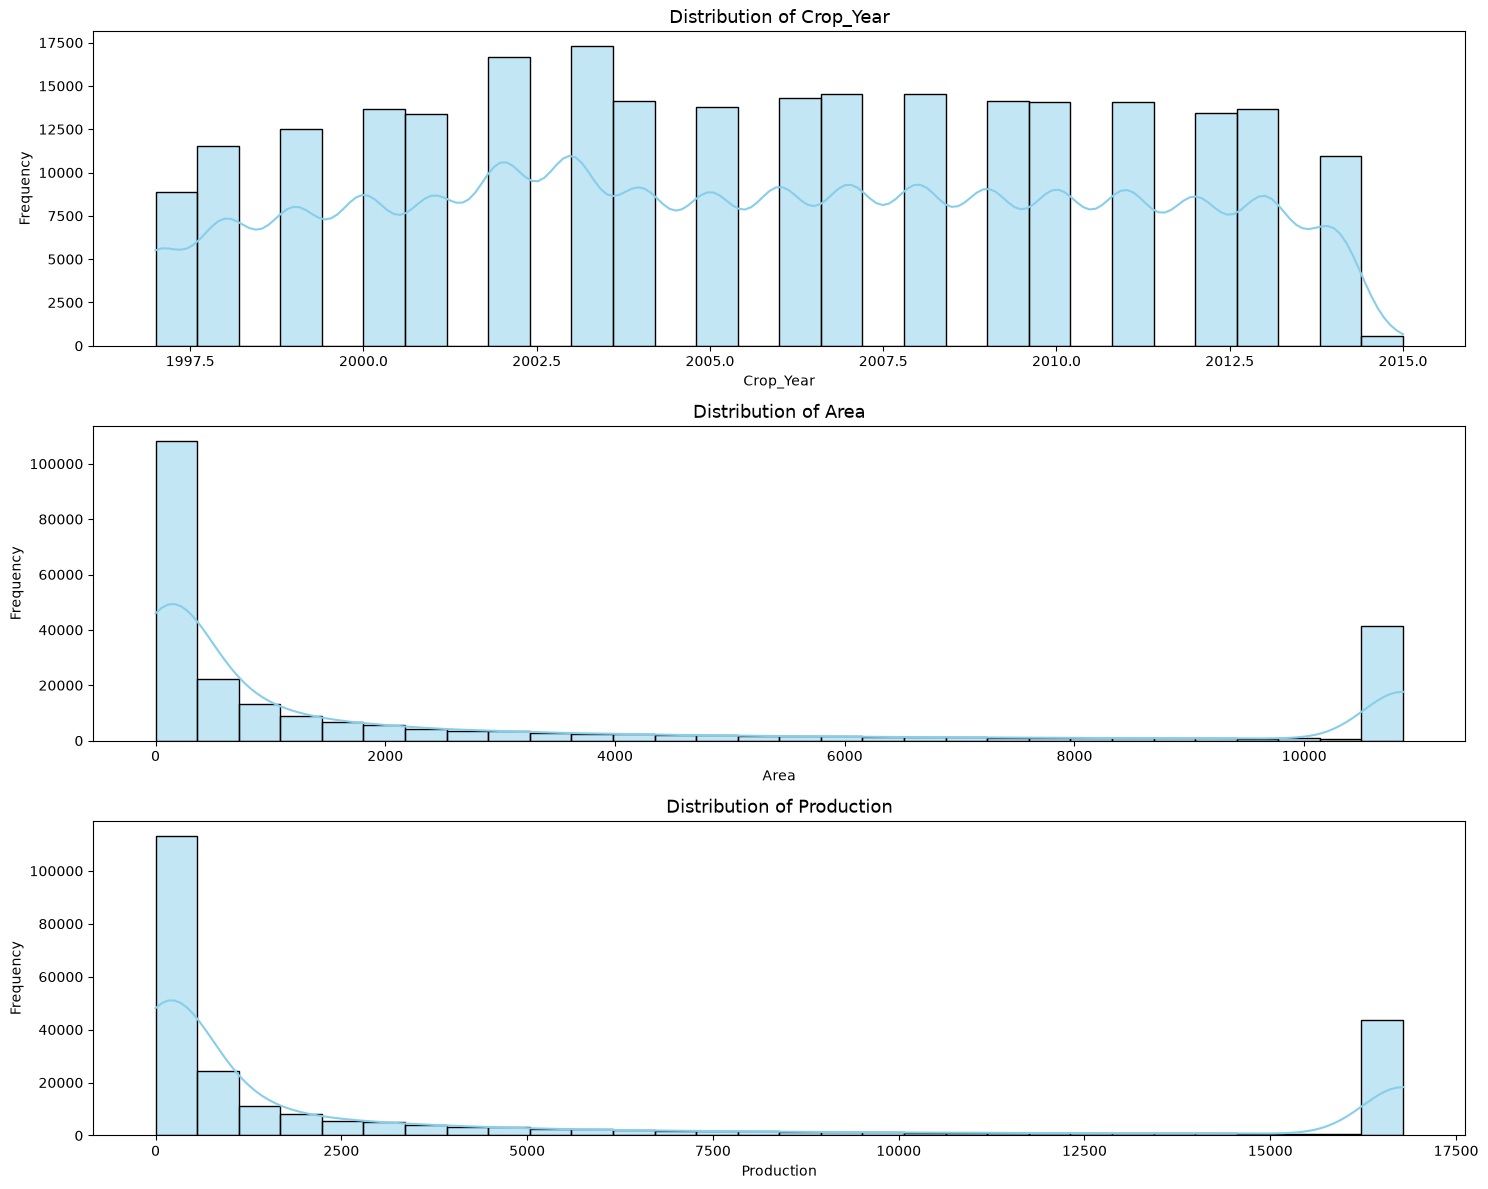

In [42]:
# Select numerical columns
numerical_cols = ['Crop_Year', 'Area', 'Production']

# Plot all distributions
plt.figure(figsize=(15, 12))

for i, col in enumerate(numerical_cols, 1):

    plt.subplot(3, 1, i)

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        color='skyblue',
        edgecolor='black'
    )

    plt.title(f'Distribution of {col}', fontsize=13)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Interprtation:-
#### 1.The crop year distribution indicates that number of agriculture records varies over year. The highest frequency of observation is seen around 2002-2003,while fewer records are available in the final yeas.This suggests that the dataset has an uneven distribution of records across different years.
#### 2.The area distribution is highly positively skewed(right-skewed).This indicates that most crop records are associated with smaller cultivated areas,while only a few records have very large cultivated areas.The distribution also shows extreme values that require further investigation.
#### 3.The production distribution is highly positively skewed.Most observations have relatively low production values,where as small number of observations have very high production may represent large-scale agricultural production or unusual data values and should be investigated further.


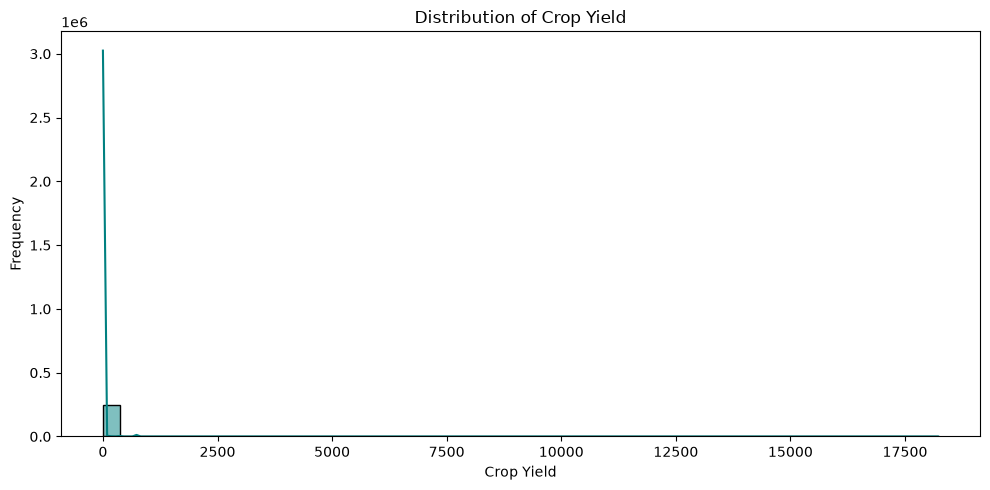

In [43]:
# Distribution of Crop Yield

plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Yield', bins=50, kde=True, color='teal')

plt.title('Distribution of Crop Yield')
plt.xlabel('Crop Yield')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#### Interpretation:-The yield distribution is highly positively skewed. Most observations have comparatively lower yield values, while a few extremely high values increase the overall mean. This indicates substantial variation in crop productivity.

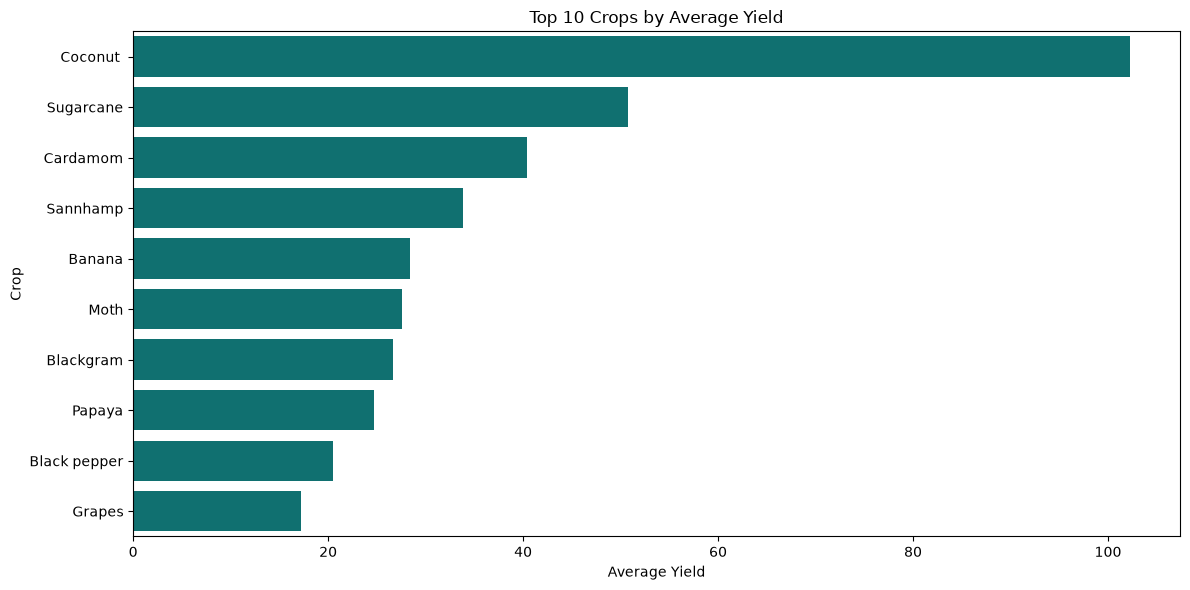

In [44]:
# Top 10 Crops by Average Yield

crop_yield = (
    df.groupby('Crop')['Yield']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=crop_yield.values,
    y=crop_yield.index,
    color='teal'
)

plt.title('Top 10 Crops by Average Yield')
plt.xlabel('Average Yield')
plt.ylabel('Crop')

plt.tight_layout()
plt.show()

#### Interpretation :- The graph helps identify crops with higher average yield per unit of cultivated area. It provides a productivity-based comparison rather than comparing crops only by total production.

In [45]:
#Multivariate Analysis

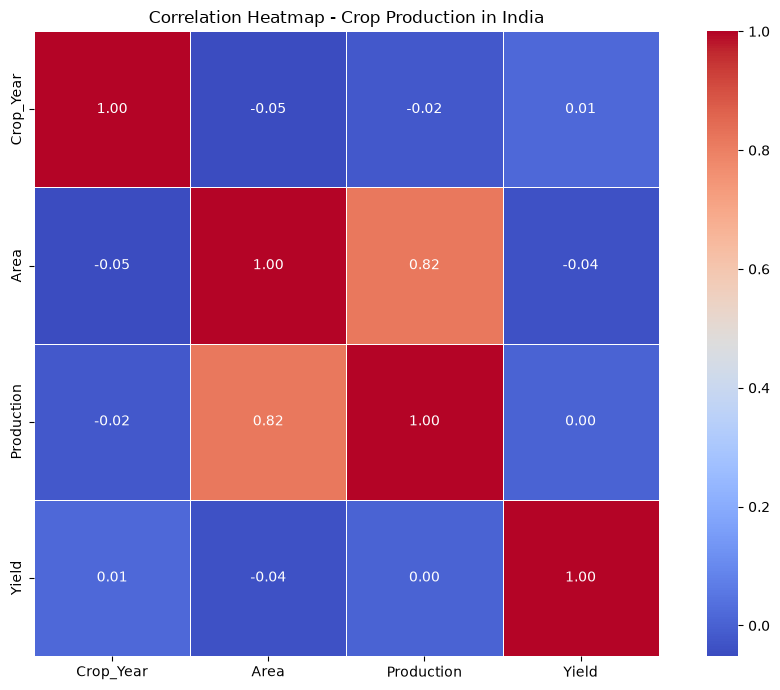

In [46]:
numerical_cols=["Crop_Year","Area","Production","Yield"]
corr=df[numerical_cols].corr()
plt.figure(figsize=(10,7))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5,square=True)
plt.title("Correlation Heatmap - Crop Production in India")
plt.tight_layout()
plt.show()

#### Interprtation:-The strong positive correlation between Area and Production indicates that larger cultivated areas are generally associated with higher production. This suggests that cultivated area is an important factor associated with agricultural output. However, correlation does not establish causation.

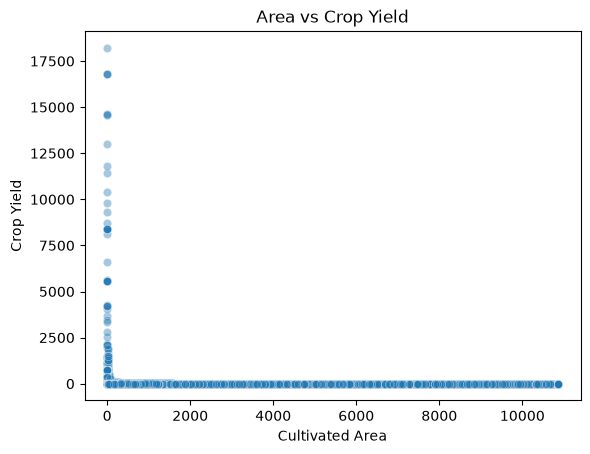

In [47]:
df["Yield"]=df["Production"]/df["Area"]
sns.scatterplot(data=df,x="Area",y="Yield",alpha=0.4)
plt.title("Area vs Crop Yield")
plt.xlabel("Cultivated Area")
plt.ylabel("Crop Yield")
plt.show()

#### Interpretation:-The scatterplot suggests that cultivated area alone does not explain crop yield. Productivity can vary across crop records even when cultivated areas are similar. Other factors, such as crop type, soil conditions, irrigation and climate, may also influence yield, although these factors are not directly tested in this analysis.

In [48]:
#Group by Analysis

In [49]:
state_analysis=(df.groupby("State_Name")["Production"].sum().sort_values(ascending=False))
display(state_analysis.head(10))

State_Name
Uttar Pradesh     1.538402e+08
Madhya Pradesh    1.018113e+08
Karnataka         9.821553e+07
Maharashtra       8.279484e+07
Bihar             7.686257e+07
Tamil Nadu        6.485396e+07
Assam             6.039020e+07
Gujarat           5.739335e+07
Andhra Pradesh    5.658684e+07
Rajasthan         5.634526e+07
Name: Production, dtype: float64

#### Interpretation:-Uttar Pradesh is the leading production-contributing state among the top 10 states in this dataset. Madhya Pradesh and Karnataka also show substantial agricultural production. The results indicate differences in agricultural output across states.

In [50]:
crop_analysis=(df.groupby("Crop")["Production"].sum().sort_values(ascending=False))
display(crop_analysis.head(10))

Crop
Rice                 1.795229e+08
Wheat                9.273045e+07
Sugarcane            9.229042e+07
Maize                8.397940e+07
Potato               5.841236e+07
Jowar                3.969661e+07
Groundnut            3.900980e+07
Gram                 3.887812e+07
Cotton(lint)         3.238957e+07
Rapeseed &Mustard    3.181885e+07
Name: Production, dtype: float64

#### Interpretation:-Rice is the major production-contributing crop in the dataset, followed by Wheat and Sugarcane. These crops account for substantial recorded agricultural output. The analysis helps identify crops that contribute significantly to overall production.

In [51]:
season_analysis=(df.groupby("Season")["Production"].sum().sort_values(ascending=False))
display(season_analysis)

Season
Kharif         4.197040e+08
Rabi           2.942827e+08
Whole Year     2.627590e+08
Summer         4.840175e+07
Winter         4.546500e+07
Autumn         2.962755e+07
Name: Production, dtype: float64

#### Interpretation :- Kharif is the leading production-contributing season in the dataset, followed by Rabi and Whole Year. This indicates that seasonal agricultural production is not equally distributed. The difference may be associated with crop selection, cultivated area and seasonal agricultural conditions.

In [52]:
year_analysis=(df.groupby("Crop_Year")["Production"].sum().sort_values(ascending=False))
display(year_analysis)

Crop_Year
2003    70536068.17
2008    64963234.49
2010    64493374.75
2002    63902076.54
2011    63649006.44
2004    63500780.07
2006    63437951.79
2005    62157597.39
2009    62008744.19
2000    61328024.10
2007    60936055.95
1999    60925026.80
2001    60355526.27
2013    60081243.48
2012    59584132.63
1998    58452364.00
1997    51172846.00
2014    47161298.31
2015     1594609.20
Name: Production, dtype: float64

#### Interpretation :- Year-wise analysis shows fluctuations in agricultural production over the study period. Production reached its highest recorded value in 2003, followed by variations in subsequent years. The sharp decrease in 2015 may indicate incomplete or limited records for that year rather than an actual decline in agricultural output. Further investigation of year-wise data coverage is required.

### Overall Conclusion :-
**The Exploratory Data Analysis of the Indian Crop Production dataset provided useful insights into agricultural production patterns across different states, crops, seasons and years.**

**The dataset contains 246,091 records, covering 33 states and union territories, 646 districts and 124 different crops.**

**During data cleaning, missing values were handled, duplicate records were checked, and outliers were identified and treated. A new feature called Yield was created to analyse crop productivity based on cultivated area and production.**

**The visual analysis showed that Area and Production distributions are positively skewed, indicating considerable variation across agricultural records. The correlation heatmap showed a strong positive relationship between cultivated area and production. Yield analysis also highlighted variations in crop productivity.**

**The GroupBy analysis identified Uttar Pradesh as the highest production-contributing state among the top 10 states. Rice recorded the highest total production among the crops analysed. Kharif was the leading production-contributing season, while 2003 recorded the highest year-wise production in the available results.**

**Overall, this project demonstrates how Python libraries such as Pandas, NumPy, Matplotlib and Seaborn can be used for data cleaning, feature engineering and exploratory data analysis.**

**The cleaned dataset is exported for further analysis and interactive dashboard development using Tableau. The findings can help understand historical agricultural production patterns and support data-driven agricultural analysis**

In [53]:
df.to_csv("Crop_Production_Cleaned.csv",index=False)
print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [54]:
import os

In [55]:
print(os.getcwd())

C:\Users\rutuk\Python Aug 2026


In [56]:
print(os.path.exists("Crop_Production_Cleaned.csv"))

True
